# Why structure? Hybrid models versus pure surrogates

A recurring argument against structured hybrid models (a physics skeleton with a
learned component) is that they inherit an implicit solve and are therefore slower
to evaluate than a plain feed-forward or recurrent neural network trained to predict
stress directly. If inference speed on the training distribution were the only
criterion, the pure surrogate would win.

This example makes the counter-argument concrete and quantitative. On a dissipative
(viscoelastic) material we compare two models trained on the *same* limited data:

* a **structured hybrid** — a Generalized Standard Material with a *known* free energy
  and a *learned but convex* dissipation potential, so the second law
  ($\mathcal{D}\geq 0$) holds **by construction**;
* a **pure surrogate** — an unconstrained recurrent network mapping the strain history
  to stress, with no thermodynamic structure.

We show that the surrogate is *more* expressive on the training set, yet the structure
buys two things it cannot: **generalization to out-of-distribution loading**, and
**guaranteed thermodynamic admissibility** on paths never seen in training. The
implicit solve is the price of a model you can trust outside the training data.

In [1]:
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import optax

jax.config.update("jax_enable_x64", True)

## Ground-truth material and training data

The reference is a nonlinear standard linear solid: an elastic spring in parallel
with a Maxwell branch whose dashpot is nonlinear (Eyring-type),
$\dot\varepsilon_v = a\,\sinh(b\,\sigma_v)$ with overstress $\sigma_v = E_1(\varepsilon-\varepsilon_v)$.
It is rate-dependent, history-dependent, and thermodynamically admissible (the flow
is monotone through the origin, so $\mathcal{D}=\sigma_v\dot\varepsilon_v\geq 0$).

Crucially, the **training data contains only stress-relaxation tests** (a fast ramp to
a strain level, then a hold) at several amplitudes. Cyclic loading is *never* shown to
either model — it is the out-of-distribution test.

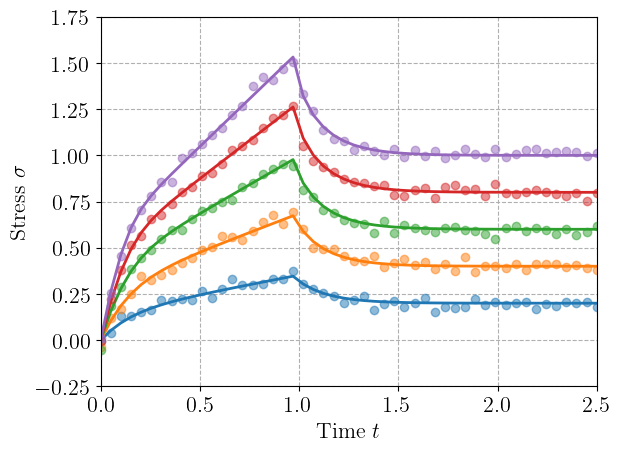

In [11]:
E_inf, E1, a, b, dt = 1.0, 4.0, 0.5, 2.8, 0.05
N = 50
T = dt*N
times = jnp.linspace(0,T,N)

def ground_truth(eps_t):
    def step(eps_v, eps):
        sigma_v = E1 * (eps - eps_v)
        eps_v_new = eps_v + dt * a * jnp.sinh(b * sigma_v)
        return eps_v_new, E_inf * eps + E1 * (eps - eps_v)

    _, sigma = jax.lax.scan(step, 0.0, eps_t)
    return sigma


def relaxation_path(eps0):
    return jnp.concatenate([jnp.linspace(0.0, eps0, 20), jnp.full(N-20, eps0)])


key = jax.random.PRNGKey(0)
amplitudes = jnp.array([0.2, 0.4, 0.6, 0.8, 1.0])
train_eps = jnp.stack([relaxation_path(a0) for a0 in amplitudes])
gt_sig = jax.vmap(ground_truth)(train_eps)
train_sig = gt_sig + 0.02 * jax.random.normal(key, (5, N))

for i, a in enumerate(amplitudes):
    h = plt.plot(times, gt_sig[i], "-");
    plt.plot(times, train_sig[i], "o",color=h[0].get_color(), alpha=0.5)
plt.xlabel("Time $t$")
plt.ylabel(r"Stress $\sigma$")
plt.show()

## Two models with the same job, different priors

**Structured hybrid.** We keep the GSM skeleton (elastic spring + Maxwell branch) and
learn *only* the dissipation, represented so that the flow rule
$\dot\varepsilon_v = f(\sigma_v)$ is **monotone and odd through the origin** for any
parameter values: $f(s) = \sum_k \mathrm{softplus}(w_k)\,\tanh(c_k s)$ with $c_k>0$.
This is a convex-dissipation-potential parameterization; it *guarantees*
$\mathcal{D}=\sigma_v\dot\varepsilon_v\geq 0$ structurally (the learned model can never
violate the second law), mirroring the neural-GSM construction in a controlled 1D
setting.

In [3]:
class StructuredHybrid(eqx.Module):
    w: jax.Array
    log_c: jax.Array
    log_E1: jax.Array

    def flow(self, s):
        c = jnp.exp(self.log_c)
        return jnp.sum(jax.nn.softplus(self.w)[None, :] * jnp.tanh(s[:, None] * c[None, :]), axis=1)

    def run(self, eps_t):
        E1_ = jax.nn.softplus(self.log_E1)

        def step(eps_v, eps):
            sigma_v = E1_ * (eps - eps_v)
            eps_v_dot = self.flow(jnp.array([sigma_v]))[0]
            return eps_v + dt * eps_v_dot, (E_inf * eps + sigma_v, sigma_v * eps_v_dot)

        _, (sigma, dissipation) = jax.lax.scan(step, 0.0, eps_t)
        return sigma, dissipation

    def simulate(self, eps_t):
        return self.run(eps_t)[0]


def make_structured():
    return StructuredHybrid(
        w=jnp.zeros(6) - 1.0, log_c=jnp.linspace(-1.0, 1.0, 6), log_E1=jnp.log(jnp.exp(4.0) - 1)
    )

**Pure surrogate.** An unconstrained GRU maps the strain (and its increment) to stress.
It has internal state, so — unlike a plain feed-forward window — it *can* represent
relaxation; but nothing constrains it to be thermodynamically admissible.

In [4]:
HIDDEN = 8


class RecurrentSurrogate(eqx.Module):
    gru: eqx.nn.GRUCell
    readout: eqx.nn.Linear

    def __init__(self, key):
        k1, k2 = jax.random.split(key)
        self.gru = eqx.nn.GRUCell(2, HIDDEN, key=k1)
        self.readout = eqx.nn.Linear(HIDDEN, 1, key=k2)

    def simulate(self, eps_t):
        deps = jnp.concatenate([jnp.zeros(1), jnp.diff(eps_t)])
        inputs = jnp.stack([eps_t, deps], axis=1)

        def step(h, inp):
            h = self.gru(inp, h)
            return h, self.readout(h)[0]

        _, sigma = jax.lax.scan(step, jnp.zeros(HIDDEN), inputs)
        return sigma

## Training (identical data, identical optimizer)

In [5]:
def loss_fn(model, paths, sigs):
    return jnp.mean((jax.vmap(model.simulate)(paths) - sigs) ** 2)


def train(model, paths, sigs, steps=2500, lr=5e-3):
    opt = optax.adam(lr)
    opt_state = opt.init(eqx.filter(model, eqx.is_inexact_array))

    @eqx.filter_jit
    def step(model, opt_state):
        loss, grad = eqx.filter_value_and_grad(loss_fn)(model, paths, sigs)
        updates, opt_state = opt.update(grad, opt_state, model)
        return eqx.apply_updates(model, updates), opt_state, loss

    for _ in range(steps):
        model, opt_state, loss = step(model, opt_state)
    return model, float(loss)


structured, mse_s = train(make_structured(), train_eps, train_sig)
surrogate, mse_u = train(RecurrentSurrogate(jax.random.PRNGKey(3)), train_eps, train_sig)

print(f"training MSE   structured hybrid = {mse_s:.2e}   pure surrogate = {mse_u:.2e}")

training MSE   structured hybrid = 1.35e-03   pure surrogate = 4.11e-04


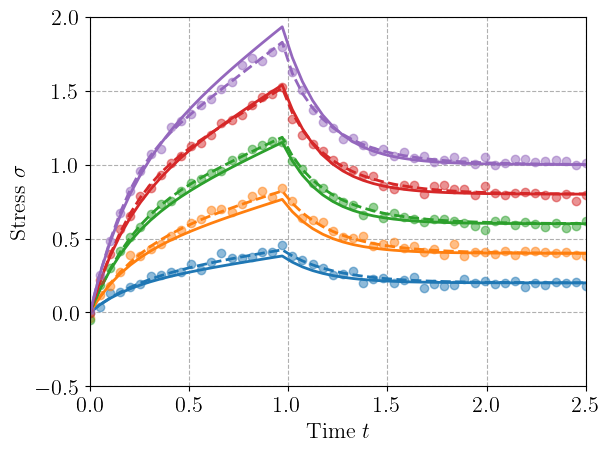

In [6]:
pred_structured = jax.vmap(structured.simulate)(train_eps)
for i, a in enumerate(amplitudes):
    h = plt.plot(times, gt_sig[i], "--");
    plt.plot(times, pred_structured[i], "-",color=h[0].get_color());
    plt.plot(times, train_sig[i], "o",color=h[0].get_color(), alpha=0.5)
plt.xlabel("Time $t$")
plt.ylabel(r"Stress $\sigma$")
plt.show()

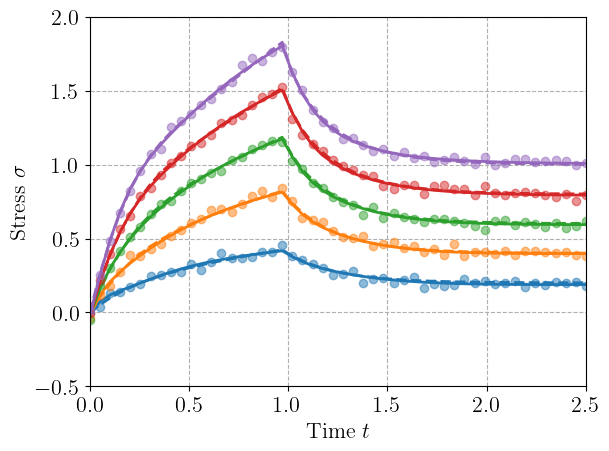

In [7]:
pred_surrogate = jax.vmap(surrogate.simulate)(train_eps)
for i, a in enumerate(amplitudes):
    h = plt.plot(times, gt_sig[i], "--");
    plt.plot(times, pred_surrogate[i], "-",color=h[0].get_color());
    plt.plot(times, train_sig[i], "o",color=h[0].get_color(), alpha=0.5)
plt.xlabel("Time $t$")
plt.ylabel(r"Stress $\sigma$")
plt.show()

## Test 1 — out-of-distribution loading

Both models are now driven by a **cyclic** strain history, a loading mode entirely
absent from the relaxation-only training set.

OOD cyclic RMSE   structured = 5.029e-01   surrogate = 4.141e-01   (0.8x worse)
certified dissipation along OOD path:  min D = 0.00e+00  (>= 0 by construction)


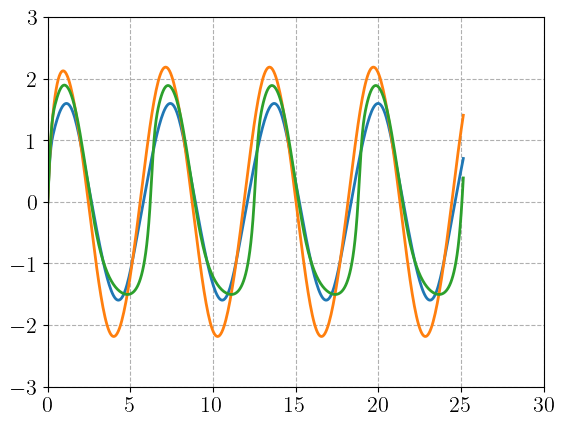

In [8]:
def cyclic(n, amp, ncycles):
    times = jnp.linspace(0.0, 2 * jnp.pi * ncycles, n)
    return times, amp * jnp.sin(times)


times, ood_eps = cyclic(400, 1.3, 4)
ood_sig = ground_truth(ood_eps)
pred_s, diss_s = structured.run(ood_eps)
pred_u = surrogate.simulate(ood_eps)

rmse_s = float(jnp.sqrt(jnp.mean((pred_s - ood_sig) ** 2)))
rmse_u = float(jnp.sqrt(jnp.mean((pred_u - ood_sig) ** 2)))
print(f"OOD cyclic RMSE   structured = {rmse_s:.3e}   surrogate = {rmse_u:.3e}   ({rmse_u / rmse_s:.1f}x worse)")
print(f"certified dissipation along OOD path:  min D = {float(jnp.min(diss_s)):.2e}  (>= 0 by construction)")

plt.plot(times, ood_sig)
plt.plot(times, pred_s.T)
plt.plot(times, pred_u.T)

## Test 2 — thermodynamic admissibility on an unseen path

A passive dissipative material, held at fixed strain, must **relax** toward
equilibrium: $|\sigma|$ can only decrease during a hold, never grow (growth would mean
the material spontaneously produces mechanical energy). We apply a load–reverse–hold
history — a *negative* hold, never seen in the positive-only training data — and track
the stress during the hold.

In [9]:
adm_eps = jnp.concatenate(
    [jnp.linspace(0, 0.7, 20), jnp.full(50, 0.7), jnp.linspace(0.7, -0.7, 40), jnp.full(90, -0.7)]
)
adm_gt = ground_truth(adm_eps)
adm_s = structured.simulate(adm_eps)
adm_u = surrogate.simulate(adm_eps)

hold = slice(110, 200)  # the negative-hold segment
growth_gt = float(jnp.max(jnp.diff(jnp.abs(adm_gt[hold]))))
growth_s = float(jnp.max(jnp.diff(jnp.abs(adm_s[hold]))))
growth_u = float(jnp.max(jnp.diff(jnp.abs(adm_u[hold]))))
print("max increase of |stress| during the OOD hold  (must be <= 0 for a passive material):")
print(f"  ground truth        : {growth_gt:+.2e}")
print(f"  structured hybrid   : {growth_s:+.2e}   (relaxes -> admissible)")
print(f"  pure surrogate      : {growth_u:+.2e}   (|stress| GROWS -> generates energy, non-physical)")

max increase of |stress| during the OOD hold  (must be <= 0 for a passive material):
  ground truth        : +0.00e+00
  structured hybrid   : -1.27e-11   (relaxes -> admissible)
  pure surrogate      : +1.63e-03   (|stress| GROWS -> generates energy, non-physical)


## Results

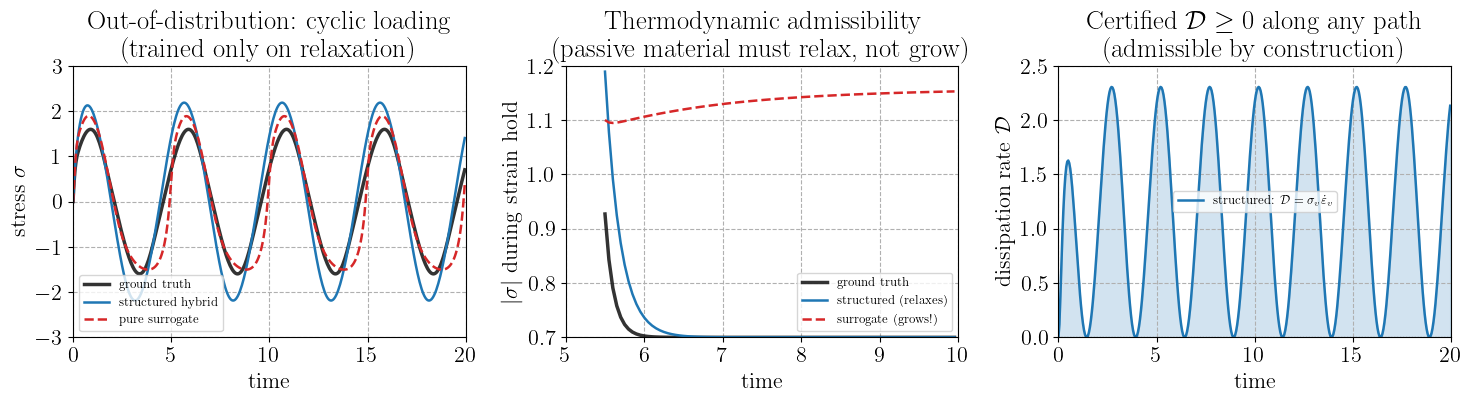

In [10]:
t_ood = jnp.arange(len(ood_eps)) * dt
t_adm = jnp.arange(len(adm_eps)) * dt
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))

ax[0].plot(t_ood, ood_sig, "k-", lw=2.5, alpha=0.8, label="ground truth")
ax[0].plot(t_ood, pred_s, "C0-", lw=1.8, label="structured hybrid")
ax[0].plot(t_ood, pred_u, "C3--", lw=1.8, label="pure surrogate")
ax[0].set_xlabel("time")
ax[0].set_ylabel(r"stress $\sigma$")
ax[0].set_title("Out-of-distribution: cyclic loading\n(trained only on relaxation)")
ax[0].legend(fontsize=9)

th = t_adm[hold]
ax[1].plot(th, jnp.abs(adm_gt[hold]), "k-", lw=2.5, alpha=0.8, label="ground truth")
ax[1].plot(th, jnp.abs(adm_s[hold]), "C0-", lw=1.8, label="structured (relaxes)")
ax[1].plot(th, jnp.abs(adm_u[hold]), "C3--", lw=1.8, label="surrogate (grows!)")
ax[1].set_xlabel("time")
ax[1].set_ylabel(r"$|\sigma|$ during strain hold")
ax[1].set_title("Thermodynamic admissibility\n(passive material must relax, not grow)")
ax[1].legend(fontsize=9)

ax[2].plot(t_ood, diss_s, "C0-", lw=1.8, label=r"structured: $\mathcal{D}=\sigma_v\dot\varepsilon_v$")
ax[2].axhline(0, color="k", lw=0.8, ls=":")
ax[2].fill_between(t_ood, 0, diss_s, alpha=0.2, color="C0")
ax[2].set_xlabel("time")
ax[2].set_ylabel(r"dissipation rate $\mathcal{D}$")
ax[2].set_title(r"Certified $\mathcal{D}\geq 0$ along any path" + "\n(admissible by construction)")
ax[2].legend(fontsize=9)

fig.tight_layout()
plt.show()

## Discussion

The comparison is deliberately unfavorable to the structured model on the axis its
critics emphasize: the surrogate is *more* expressive and fits the training data at
least as well, and it is cheaper to evaluate (no implicit solve). Yet on data it was
not trained on, the structured hybrid is several times more accurate, and — the
decisive point — it is **thermodynamically admissible by construction on every path**,
whereas the surrogate silently generates energy during an unseen hold. A model that
violates the second law cannot be trusted in a finite-element simulation: its tangent
can lose positive-definiteness and break the global equilibrium iteration.

The right conclusion is not "structure beats surrogates" but that the two occupy
different points on a single spectrum that this framework spans. Structure buys
data-efficiency, extrapolation, and guaranteed admissibility; a surrogate buys
inference speed on the training distribution. Because both are expressible here, the
structured model is the natural object to *trust and calibrate*, and — where raw speed
is required — to *distill a fast surrogate from*, using the structured model as the
certifier of physical admissibility.